# Data exploration: OTTO e-commerce sessions

Four weeks of anonymized shopping sessions from OTTO. Each event is a click, a cart addition or an order
on one product (`aid`). The task is to predict, partway through a session, which products the shopper
will click next, add to cart and order.

Reads `data/processed/train_events`, written by `scripts/prepare_data.py`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
TYPES = {0: "clicks", 1: "carts", 2: "orders"}

ev = pq.read_table(DATA / "train_events").to_pandas()
print(f"events: {len(ev):,} | sessions: {ev['session'].nunique():,} | items: {ev['aid'].nunique():,}")
print("from", pd.to_datetime(ev["ts"].min(), unit="s"), "to", pd.to_datetime(ev["ts"].max(), unit="s"))

events: 216,716,096 | sessions: 12,899,779 | items: 1,855,603
from 2022-07-31 22:00:00 to 2022-08-28 21:59:59


## Event types

In [2]:
by_type = ev["type"].map(TYPES).value_counts()
pd.DataFrame({"events": by_type, "share": (by_type / len(ev)).round(4)})

,events,share
type,,
clicks,194720954,0.8985
carts,16896191,0.0780
orders,5098951,0.0235


## Activity per day

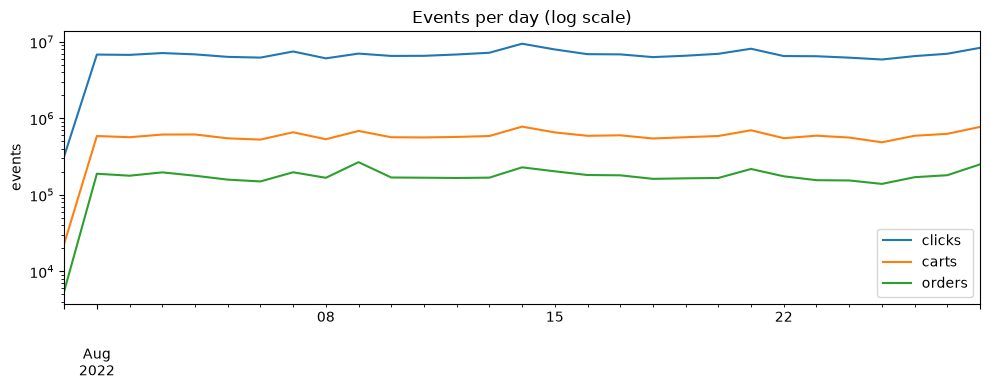

In [3]:
daily = ev.groupby([ev["ts"] // 86400, "type"]).size().unstack()
daily.index = pd.to_datetime(daily.index, unit="D")
daily.columns = [TYPES[c] for c in daily.columns]

ax = daily.plot(figsize=(10, 4), logy=True, title="Events per day (log scale)")
ax.set_xlabel("")
ax.set_ylabel("events")
plt.tight_layout()
plt.show()

## Session length

count    12899779.0
mean           16.8
std            33.6
min             2.0
50%             6.0
90%            39.0
99%           176.0
max           500.0


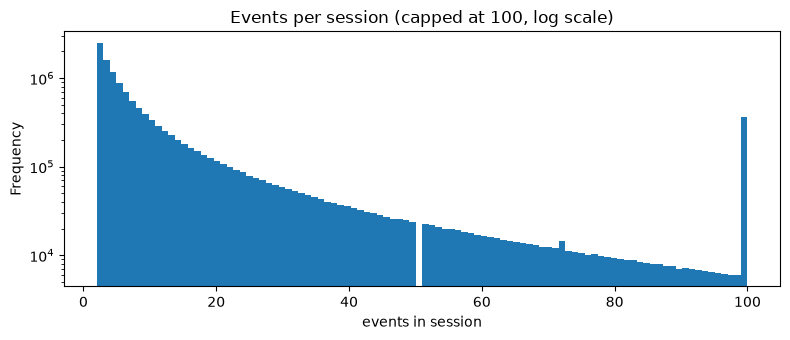

In [4]:
sess_len = ev.groupby("session").size()
print(sess_len.describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_string())

ax = sess_len.clip(upper=100).plot.hist(bins=100, figsize=(8, 3.5), logy=True,
                                        title="Events per session (capped at 100, log scale)")
ax.set_xlabel("events in session")
plt.tight_layout()
plt.show()

## Item popularity

In [5]:
item_counts = ev["aid"].value_counts()
top_1pct = item_counts.head(len(item_counts) // 100).sum() / len(ev)
print(f"items: {len(item_counts):,}")
print(f"share of all events on the top 1% of items: {top_1pct:.1%}")
print(f"items with fewer than 10 events: {(item_counts < 10).mean():.1%}")
del ev

items: 1,855,603
share of all events on the top 1% of items: 38.2%
items with fewer than 10 events: 25.1%


## How often do shoppers act on items they already touched?

For test-week sessions: the share of next clicks, carted items and ordered items that the shopper had
already interacted with before the cut. This is why the session's own history is the first candidate
source, and why recency ends up as the strongest ranking feature.

In [7]:
inp = pd.read_parquet(DATA / "test_input", columns=["session", "aid"]).drop_duplicates()
inp["seen"] = True
labels = pd.read_parquet(DATA / "test_labels")

answers = {"clicks": labels[["session", "click"]].dropna().rename(columns={"click": "aid"})}
for t in ["carts", "orders"]:
    answers[t] = labels[["session", t]].dropna().explode(t).rename(columns={t: "aid"})

rows = {}
for t, a in answers.items():
    a = a.astype({"session": "int64", "aid": "int64"})
    m = a.merge(inp.astype({"session": "int64", "aid": "int64"}), on=["session", "aid"], how="left")
    rows[t] = {"answers": len(m), "already touched": round(float(m["seen"].notna().mean()), 4)}
pd.DataFrame(rows).T

,answers,already touched
clicks,1755489.0,0.3238
carts,581121.0,0.3121
orders,313045.0,0.5946
